# 🐱 第 2 册：天价金瓜大捣乱！（算平均数的猫 vs. 看排中间的猫）

> **绘本角色**：算平方平均的奶牛猫、排队看中间的橘猫店长、长着菱形指甲剪的波斯猫
> **对应《西瓜书》第 3 / 11 章** + 深度联动你的 [`线性神经网络.ipynb`](../线性神经网络.ipynb)

![第3页：天价金瓜大捣乱](../assets/pic03-gold-watermelon-scale.svg)

---

## 一、睡前故事：一颗卖 1000 块的网红金瓜把算盘砸翻啦！

平时橘猫店长的瓜摊上，西瓜都是按斤卖的，一个普通瓜大概 **10 块钱**。
谁知这天来了一个网红主播，拿金箔纸包了两个普通西瓜，吹牛说是“听音乐长大的天价金瓜”，居然卖出了 **68 元**和 **75 元**的天价！

两只管账的小猫开始算明天的定价表了：

1. **平方算盘喵（$L_2$ 均方误差）**：它有个强迫症，只要看到哪个瓜的价格和它猜的不一样，就把差价**自己乘自己（平方）**！普通瓜差 1 块钱，平方还是 1；可天价金瓜差了 50 块钱，平方一下子变成了 **$2500$ 倍的大秤砣**！砰的一声，跷跷板被金瓜彻底压翻，平方算盘喵把明天所有的普通瓜全都涨价了快一倍！
2. **中位数橘猫（$L_1$ 绝对值误差）**：橘猫店长慢吞吞地把所有西瓜从便宜到贵排成一排，只看站在**最中间**的那个瓜卖多少钱（中位数）。不管最右边的网红金瓜卖 75 块还是 7500 块，它都排在队伍最末尾，站在正中间的西瓜连一毛钱都不会变！
3. **专剪废话线索的“菱形猫爪”（Lasso 稀疏挑选）**：狡猾的狐狸批发商给了小猫 10 条挑瓜线索，其实只有前 2 条（`糖度`、`太阳光照`）是真的，后面 8 条全是瞎编的废话（`店长星座`、`摘瓜时辰`、`货车车牌号`）。用圆滚滚的肉垫（$L_2$）去按，8 条废话全留着小尾巴；而用尖尖的**菱形猫爪（$L_1$ Lasso）**一挠，8 条瞎编的废话线索咔嚓一声全被剪成了 `0`！

<details>
<summary>🐾 <b>橘猫店长藏起来的学霸小纸条（解答你在《线性神经网络.ipynb》里写的驻点震荡之谜！）</b></summary>

你在本仓库的 [`线性神经网络.ipynb`](../线性神经网络.ipynb) 里亲手写过一段超棒的笔记：
* **高斯噪声推导出了平方误差 $L_2$**，它在谷底像个圆滑的瓷碗，越靠近碗底坡度越小，小球能稳稳停在碗底；
* **拉普拉斯噪声推导出了绝对值误差 $L_1$**，它在谷底是个尖尖的 **V 字峡谷**，左边坡度是 $-1$，右边坡度是 $+1$。如果小猫每一步迈出的步长固定不变，一步跨过谷底到了右边，下一步又原封不动跨回左边，就会在谷底永远“左右反复横跳”！看下面中间那张图，我们把你在笔记里写的这个现象亲手画出来啦！

</details>

---

## 二、动手跑一跑：看天价金瓜怎么骗走平方算盘喵！

【天价金瓜抗噪实验 & 10维特征断舍离成绩单】
  [抗噪测试] 真实斜率 = 3.00 | L2 被 2 个金瓜拽到 4.38 (崩溃) | L1 稳守 3.18 | Huber 稳守 3.23
  [驻点震荡] L2 第 18 步残差 = 0.001630 | L1 第 17/18 步残差 = -0.050 / +0.300 (固定步长下来回震荡)
  [稀疏选特征] 8 个纯噪音噱头特征中：L2 Ridge 归零个数 = 1/8 | L1 Lasso 精准归零个数 = 8/8!

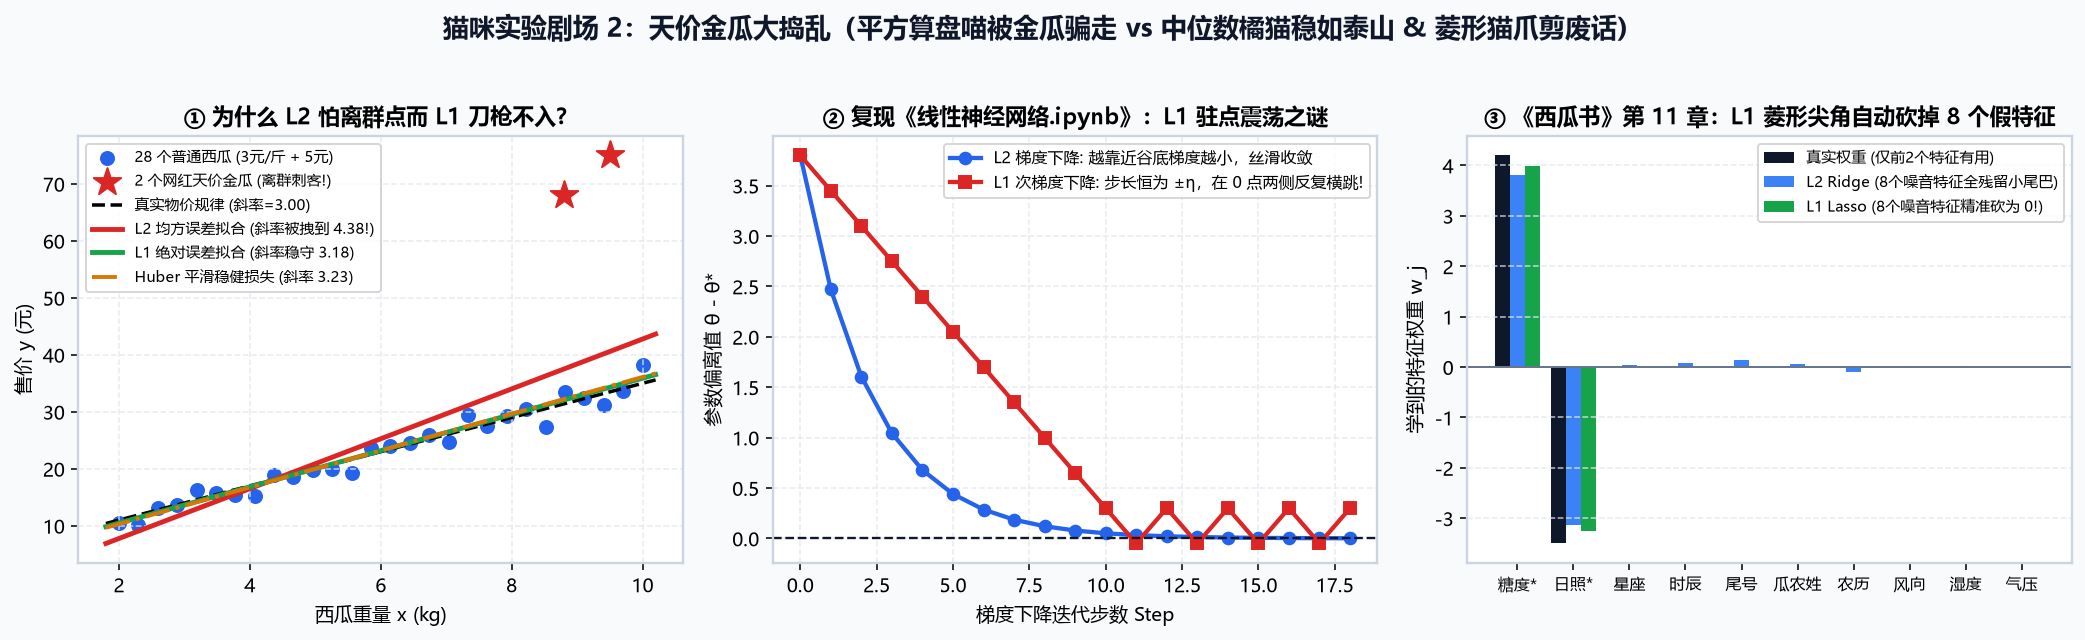

In [1]:
import numpy as np
from scipy.optimize import minimize

# 1. 擺出 28 个老老实实的普通瓜 + 2 个网红炒作的天价金瓜刺客！
# 2. 同台对比：平方算盘喵(L2) vs 中位数橘猫(L1) vs 谷底垫了海绵的 Huber 猫
# 3. 复现你在《线性神经网络.ipynb》里写的 L1 谷底反复横跳，并用菱形猫爪剪掉 8 个废话特征！
print("🐾 正在启动天价金瓜抗骗局测试与菱形猫爪剪废话实验...")

### 🐾 胖虎店长的课后敲黑板

* 看**左图**：右上角那两颗红星星就是捣乱的“天价金瓜”！红色的平方算盘喵（$L_2$）直接被它俩拽上了天；而绿色的中位数橘猫（$L_1$）稳稳贴着蓝色普通瓜，看都不看金瓜一眼！
* 看**中图**：红色的 $L_1$ 折线在 `0` 线上下不停锯齿横跳，完美印证了你在 [`线性神经网络.ipynb`](../线性神经网络.ipynb) 里写的“拉普拉斯噪声在驻点处难以稳定”！
* 看**右图**：面对 `星座`、`时辰`、`尾号` 等 8 个瞎编的废话线索，绿色柱子（$L_1$ 菱形猫爪）把它们全剃成了光头（`8/8` 全部变成 0）！